
# EXERCISES F: Datasets on Use


In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1 Reducing Dimensionality

### 1.1 Reducing 2D Artificial Datasets into 1D Datasets

Use the following 2D artificial dataset generator, and obtain various binary classification problems. Then:

1. Plot these 2D datasets.
2. Apply some classification technique to them, e.g., a logistic regression.
3. Evaluate and plot the result of the obtained classifiers.
4. Transform the dataset by PCA into 1D datasets (use `PCA` in `sklearn.decomposition`):
5. Apply the same classification technique to the obtained 1D datasets.
6. Evaluate and plot the result of the obtained classifiers.
7. Compare the two kinds of results (the ones in 2D vs. the ones in 1D).

    

In [2]:
import numpy as np
from numpy.random import Generator, PCG64

def generate_data(mean_A, mean_B, N_A, N_B, random_seed=42):
    # Initialize the random number generator with a seed for reproducibility
    rng = Generator(PCG64(random_seed))
    
    # Covariance matrices (assuming identity covariance)
    cov_A = np.identity(2)
    cov_B = np.identity(2)
    
    # Generate the multivariate normal samples for both sets
    X_A = rng.multivariate_normal(mean_A, cov_A, size=N_A)
    X_B = rng.multivariate_normal(mean_B, cov_B, size=N_B)
    
    X = np.concatenate((X_A, X_B))
    
    # Create the labels array: 0 for class A, 1 for class B
    Y = np.array([0] * N_A + [1] * N_B)
    
    return X, Y, X_A, X_B

mean_A = [5, 7]
mean_B = [3, 10]
N_A = 200
N_B = 200
X, Y, X_A, X_B = generate_data(mean_A, mean_B, N_A, N_B)

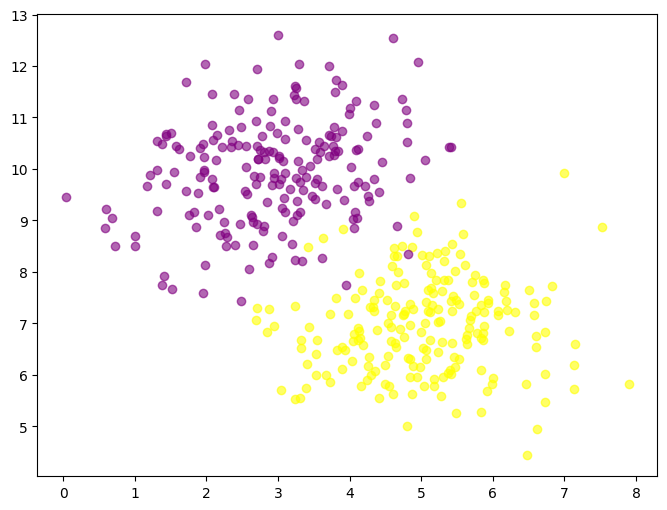

In [3]:
plt.figure(figsize=(8, 6))
plt.scatter(X_A[:, 0], X_A[:, 1], color='yellow', label='Class A', alpha=0.6)
plt.scatter(X_B[:, 0], X_B[:, 1], color='purple', label='Class B', alpha=0.6) 
plt.show()

In [4]:
from sklearn.decomposition import PCA

nb_components = 2
pca = PCA(n_components = nb_components)
X_pca = pca.fit_transform(X)
pca.explained_variance_ratio_

array([0.78610003, 0.21389997])

### 1.2 Reducing the dimensionality of a true dataset
Let us work with the dataset "Optical recognition of handwritten digits dataset" directly available in `sklearn_datasets` (see originally https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits) which is a simpler alternative to MNIST:

In [5]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

data = load_digits()
X_train, X_test, Y_train, Y_test = train_test_split(data['data'], data['target'], test_size=0.2, random_state=43)

print(f'Number of training instances: {X_train.shape[0]}')
print(f'Initial number of dimensions: {X_train.shape[1]}')

Number of training instances: 1437
Initial number of dimensions: 64


Use again `sklearn.decomposition.PCA` to reduce the dimensionality of this dataset: 

1. Plot how this dimensionality reduction behaves depending on the number of chosen pca components and the ratio of explained variance (the sum of coefficients) against the number of dimensions (the number of coefficients).
2. Give what seems to be an appropriate range for the number of dimensions to use for PCA.

## 2. Binary classification over a text dataset

Here, the dataset is made of texts corresponding to reviews of movies from the IMDB site. The binary classification problem is to separate them into positive and negative reviews. 

(This exercise/example is taken from Chollet 2021, Chapter 4)

### 2.1 Load and explore the dataset

Use the code below to download the classic IMDB dataset from `Tensorflow`.

N.B.: Warnings may occur from Tensorflow if not installed, but with no impact to the effective load of the dataset.

In [6]:
from tensorflow.keras.datasets import imdb
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=10000)

I0000 00:00:1792149588.407440  743234 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792149588.407883  743234 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792149588.436172  743234 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792149589.328008  743234 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [7]:
train_data.shape, test_data.shape

((25000,), (25000,))

The texts are represented into word occurrences which are encoded by their respective frequency
(the '10000' appearing above indicates that only the 10000 most frequent words are on use)

In [8]:
#print the first sample of the dataset:
train_data[0]

[1,
 14,
 22,
 16,
 43,
 530,
 973,
 1622,
 1385,
 65,
 458,
 4468,
 66,
 3941,
 4,
 173,
 36,
 256,
 5,
 25,
 100,
 43,
 838,
 112,
 50,
 670,
 2,
 9,
 35,
 480,
 284,
 5,
 150,
 4,
 172,
 112,
 167,
 2,
 336,
 385,
 39,
 4,
 172,
 4536,
 1111,
 17,
 546,
 38,
 13,
 447,
 4,
 192,
 50,
 16,
 6,
 147,
 2025,
 19,
 14,
 22,
 4,
 1920,
 4613,
 469,
 4,
 22,
 71,
 87,
 12,
 16,
 43,
 530,
 38,
 76,
 15,
 13,
 1247,
 4,
 22,
 17,
 515,
 17,
 12,
 16,
 626,
 18,
 2,
 5,
 62,
 386,
 12,
 8,
 316,
 8,
 106,
 5,
 4,
 2223,
 5244,
 16,
 480,
 66,
 3785,
 33,
 4,
 130,
 12,
 16,
 38,
 619,
 5,
 25,
 124,
 51,
 36,
 135,
 48,
 25,
 1415,
 33,
 6,
 22,
 12,
 215,
 28,
 77,
 52,
 5,
 14,
 407,
 16,
 82,
 2,
 8,
 4,
 107,
 117,
 5952,
 15,
 256,
 4,
 2,
 7,
 3766,
 5,
 723,
 36,
 71,
 43,
 530,
 476,
 26,
 400,
 317,
 46,
 7,
 4,
 2,
 1029,
 13,
 104,
 88,
 4,
 381,
 15,
 297,
 98,
 32,
 2071,
 56,
 26,
 141,
 6,
 194,
 7486,
 18,
 4,
 226,
 22,
 21,
 134,
 476,
 26,
 480,
 5,
 144,
 30,
 5535,
 18,

In [9]:
#labeling is 0: negative review;  1: positive review 
train_labels[0]

np.int64(1)

It is possible to decode the reviews back into text by using the associated dictionary:

In [10]:
word_index = imdb.get_word_index()
word_index

{'fawn': 34701,
 'tsukino': 52006,
 'nunnery': 52007,
 'sonja': 16816,
 'vani': 63951,
 'woods': 1408,
 'spiders': 16115,
 'hanging': 2345,
 'woody': 2289,
 'trawling': 52008,
 "hold's": 52009,
 'comically': 11307,
 'localized': 40830,
 'disobeying': 30568,
 "'royale": 52010,
 "harpo's": 40831,
 'canet': 52011,
 'aileen': 19313,
 'acurately': 52012,
 "diplomat's": 52013,
 'rickman': 25242,
 'arranged': 6746,
 'rumbustious': 52014,
 'familiarness': 52015,
 "spider'": 52016,
 'hahahah': 68804,
 "wood'": 52017,
 'transvestism': 40833,
 "hangin'": 34702,
 'bringing': 2338,
 'seamier': 40834,
 'wooded': 34703,
 'bravora': 52018,
 'grueling': 16817,
 'wooden': 1636,
 'wednesday': 16818,
 "'prix": 52019,
 'altagracia': 34704,
 'circuitry': 52020,
 'crotch': 11585,
 'busybody': 57766,
 "tart'n'tangy": 52021,
 'burgade': 14129,
 'thrace': 52023,
 "tom's": 11038,
 'snuggles': 52025,
 'francesco': 29114,
 'complainers': 52027,
 'templarios': 52125,
 '272': 40835,
 '273': 52028,
 'zaniacs': 52130,

In [11]:
reverse_word_index = dict(
    [(value, key) for (key, value) in word_index.items()])
reverse_word_index

{34701: 'fawn',
 52006: 'tsukino',
 52007: 'nunnery',
 16816: 'sonja',
 63951: 'vani',
 1408: 'woods',
 16115: 'spiders',
 2345: 'hanging',
 2289: 'woody',
 52008: 'trawling',
 52009: "hold's",
 11307: 'comically',
 40830: 'localized',
 30568: 'disobeying',
 52010: "'royale",
 40831: "harpo's",
 52011: 'canet',
 19313: 'aileen',
 52012: 'acurately',
 52013: "diplomat's",
 25242: 'rickman',
 6746: 'arranged',
 52014: 'rumbustious',
 52015: 'familiarness',
 52016: "spider'",
 68804: 'hahahah',
 52017: "wood'",
 40833: 'transvestism',
 34702: "hangin'",
 2338: 'bringing',
 40834: 'seamier',
 34703: 'wooded',
 52018: 'bravora',
 16817: 'grueling',
 1636: 'wooden',
 16818: 'wednesday',
 52019: "'prix",
 34704: 'altagracia',
 52020: 'circuitry',
 11585: 'crotch',
 57766: 'busybody',
 52021: "tart'n'tangy",
 14129: 'burgade',
 52023: 'thrace',
 11038: "tom's",
 52025: 'snuggles',
 29114: 'francesco',
 52027: 'complainers',
 52125: 'templarios',
 40835: '272',
 52028: '273',
 52130: 'zaniacs',

In [12]:
reverse_word_index.get(34701)  

'fawn'

In [13]:
reverse_word_index.get(2)  

'and'

In [14]:
# Here is what happens when the code does not exist:
reverse_word_index.get(10000000, "?")  

'?'

In [15]:
# Here is the decoding of the first sample: 
decoded_review = " ".join(
    [reverse_word_index.get(i - 3, "?") for i in train_data[0]])
decoded_review

"? this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert ? is an amazing actor and now the same being director ? father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for ? and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also ? to the two little boy's that played the ? of norman and paul they were just brilliant children are often left out of the ? list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for what they have done don't you th

In [16]:
data = [1,14,22,14]
decoded_review = " ".join(
    [reverse_word_index.get(i - 3, "?") for i in data])
decoded_review

'? this film this'

### 2.2 Vectorization the dataset 
As seen in the course, using a dictionary is not an adequate representation for most ML techniques. 
It is better to vectorize the word occurrences into binary arrays.

In [17]:
import numpy as np
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        for j in sequence:
            results[i, j] = 1.
    return results
    
x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)

y_train = np.asarray(train_labels).astype("float32")
y_test = np.asarray(test_labels).astype("float32")

In [18]:
x_train[0], y_train[0]

(array([0., 1., 1., ..., 0., 0., 0.], shape=(10000,)), np.float32(1.0))

### 3.3 Obtain a generalization/model  
Use the above vectorized dataset and train a simple binary classifier over it.

N.B.: Without Tensorflow, it can take some time, but not so much, e.g., with `SGDClassifier`.

### 3.4 Evaluate the obtained generalization/model

- Try and observe the predictions of the classifer on some single data.
- Use the whole test dataset to evaluate the classifier.
- Plot the confusion matrix, and observe the error cases.
- Try to improve the classifier.
 